# Détection d'anomalies bancaires par partitionnement

Ce notebook documente la partie clustering et évaluation du projet ChronoBank AI, dont l'objectif est de repérer des journées de comportement suspect à partir de données bancaires simulées. Chaque observation correspond à une journée d'activité d'un utilisateur, décrite par treize indicateurs comportementaux construits en amont. L'approche est non supervisée : les algorithmes de partitionnement regroupent les journées similaires, puis un score fondé sur l'éloignement au centre du groupe permet de signaler les journées atypiques. Les étiquettes d'attaque simulées ne servent qu'à évaluer a posteriori la qualité de la détection. Quatre méthodes sont comparées : KMeans, KMeans++, la classification ascendante hiérarchique (CAH agglomérative) et la CAH divisive.

## Imports et configuration

Nous commençons par charger les bibliothèques nécessaires au pipeline : NumPy et pandas pour la manipulation des données, Matplotlib pour les graphiques et SciPy pour la construction des dendrogrammes. Les algorithmes de partitionnement (KMeans, BisectingKMeans et AgglomerativeClustering) proviennent de sklearn, de même que la PCA, utilisée pour la visualisation, et les métriques d'évaluation. Ces dernières couvrent des mesures internes, comme la silhouette et l'indice de Davies Bouldin, et des mesures externes, comme la précision, le rappel et le score F1. Le style graphique est fixé dès le départ afin d'obtenir des figures homogènes dans tout le document.

In [35]:
# Imports et configuration
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Algorithmes de partitionnement et hiérarchiques
from sklearn.cluster import KMeans, BisectingKMeans, AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

# Préparation et réduction de dimension
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Métriques d'évaluation
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Configuration visuelle
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
%matplotlib inline

print("imports et configuration fait avec succés")

imports et configuration fait avec succés


## Définition et validation du schéma

Avant toute analyse, nous fixons la liste des treize variables attendues et les deux colonnes d'identification, user_id et day. Une fonction de validation vérifie la présence de ces colonnes, le caractère numérique des indicateurs et l'absence de valeurs manquantes. Cette étape sert de contrôle de cohérence entre l'équipe qui produit les données et celle qui les exploite : si le schéma change, le notebook s'arrête avec un message explicite plutôt que de produire des résultats silencieusement faux.

In [36]:
# Définition des variables attendues et validation automatique
EXPECTED_FEATURES = [
    'n_events', 'n_tx', 'n_login', 'n_failed',
    'n_new_device', 'n_foreign', 'pct_night', 'hour_mean',
    'amount_mean', 'amount_ratio', 'min_gap', 'mean_gap', 'amount_max'
]

METADATA_COLS = ['user_id', 'day']

def validate_input_data(df: pd.DataFrame) -> bool:
    """
    Vérifie la conformité de la structure des données :
    - Présence des identifiants (user_id, day)
    - Présence stricte des 13 indicateurs comportementaux
    - Contrôle des types numériques
    - Contrôle et signalement des valeurs manquantes (NaN)
    """
    missing_meta = [col for col in METADATA_COLS if col not in df.columns]
    missing_feats = [col for col in EXPECTED_FEATURES if col not in df.columns]
    
    if missing_meta:
        raise ValueError(f"Erreur schéma : colonnes d'identification manquantes -> {missing_meta}")
    if missing_feats:
        raise ValueError(f"Erreur schéma : variables manquantes -> {missing_feats}")
        
    # Vérification des types non numériques
    non_numeric = [col for col in EXPECTED_FEATURES if not pd.api.types.is_numeric_dtype(df[col])]
    if non_numeric:
        print(f"Attention : colonnes non numériques détectées -> {non_numeric}")
        
    # Contrôle des NaN
    nan_counts = df[EXPECTED_FEATURES].isna().sum()
    total_nans = nan_counts.sum()
    if total_nans > 0:
        print(f"Attention : {total_nans} valeurs manquantes détectées !")
        print(nan_counts[nan_counts > 0])
        return False
    
    print("Validation réussie : 13 features et métadonnées conformes, aucune valeur manquante.")
    return True

## Chargement du jeu de données

Le fichier features.csv est lu depuis le dossier data/processed, avec une recherche automatique du bon chemin selon que le notebook est lancé depuis la racine du projet ou depuis un dossier voisin. Le jeu contient 30000 observations et 16 colonnes : les deux identifiants, l'étiquette is_attack et les treize indicateurs. Les valeurs affichées semblent déjà centrées et réduites, ce qui explique la présence de valeurs négatives et dispense d'appliquer une normalisation supplémentaire, point essentiel pour des méthodes fondées sur des distances euclidiennes.

In [37]:
import os

os.makedirs("../clustering/graphiques", exist_ok=True)

# Remonte d'un niveau si nécessaire
if not os.path.exists("data/processed/features.csv"):
    path = "../data/processed/features.csv"
else:
    path = "data/processed/features.csv"

df = pd.read_csv(path)

print("Dataset chargé avec succès !")
print("Dimensions :", df.shape)

display(df.head())

Dataset chargé avec succès !
Dimensions : (30000, 16)


,user_id,day,is_attack,n_events,n_tx,n_login,n_failed,n_new_device,n_foreign,pct_night,hour_mean,amount_mean,amount_max,amount_ratio,min_gap,mean_gap
0,U0001,2026-01-01,0.0,1.650701,0.833335,1.899901,-0.170189,-0.077199,-0.077199,-0.351656,0.158908,1.494113,1.472459,1.333169,1.257253,1.233635
1,U0001,2026-01-02,0.0,-0.050755,0.833335,-1.008867,-0.170189,-0.077199,-0.077199,-0.351656,-0.088608,1.110378,1.092334,0.208452,-0.754072,-0.763833
2,U0001,2026-01-03,0.0,-0.050755,0.833335,-1.008867,-0.170189,-0.077199,-0.077199,-0.351656,-0.309011,1.388223,1.367566,0.957842,-0.754072,-0.763833
3,U0001,2026-01-04,0.0,0.702151,0.833335,0.445517,-0.170189,-0.077199,-0.077199,1.681502,0.890960,1.351546,1.331234,0.839547,1.824455,1.709015
4,U0001,2026-01-05,0.0,0.702151,0.833335,0.445517,-0.170189,-0.077199,-0.077199,-0.351656,0.822740,1.345525,1.325269,0.820704,1.336704,1.241254


### Validation du dataset

La fonction définie plus haut est appliquée au DataFrame chargé. Le retour vrai confirme que les treize indicateurs et les métadonnées sont conformes et qu'aucune valeur manquante n'est présente, ce qui autorise la poursuite du pipeline.

In [38]:
# Validation du dataset

validate_input_data(df)

Validation réussie : 13 features et métadonnées conformes, aucune valeur manquante.


True

## Exploration initiale

Un premier aperçu de la structure du jeu de données permet de contrôler les dimensions, les types et les noms de colonnes. Les treize indicateurs sont tous de type flottant et complets sur les 30000 lignes, tandis que user_id et day sont des chaînes de caractères. Cette inspection confirme que les données sont directement exploitables par des algorithmes numériques.

In [39]:
print(df.head())
print(df.shape)
print(df.info())
print(df.columns.tolist())

  user_id         day  is_attack  n_events      n_tx   n_login  n_failed  \
0   U0001  2026-01-01        0.0  1.650701  0.833335  1.899901 -0.170189   
1   U0001  2026-01-02        0.0 -0.050755  0.833335 -1.008867 -0.170189   
2   U0001  2026-01-03        0.0 -0.050755  0.833335 -1.008867 -0.170189   
3   U0001  2026-01-04        0.0  0.702151  0.833335  0.445517 -0.170189   
4   U0001  2026-01-05        0.0  0.702151  0.833335  0.445517 -0.170189   

   n_new_device  n_foreign  pct_night  hour_mean  amount_mean  amount_max  \
0     -0.077199  -0.077199  -0.351656   0.158908     1.494113    1.472459   
1     -0.077199  -0.077199  -0.351656  -0.088608     1.110378    1.092334   
2     -0.077199  -0.077199  -0.351656  -0.309011     1.388223    1.367566   
3     -0.077199  -0.077199   1.681502   0.890960     1.351546    1.331234   
4     -0.077199  -0.077199  -0.351656   0.822740     1.345525    1.325269   

   amount_ratio   min_gap  mean_gap  
0      1.333169  1.257253  1.233635  
1   

### Contrôle de la qualité des données

Nous vérifions ensuite l'absence de valeurs manquantes, de doublons sur le couple utilisateur et jour et de valeurs infinies, qui fausseraient les calculs de distance. Ces contrôles ne révèlent aucun problème. L'examen de l'étiquette is_attack met en évidence un fort déséquilibre : 29700 journées normales contre 300 attaques simulées, soit exactement 1 pour cent. Ce constat oriente la suite du travail, car l'exactitude globale serait trompeuse sur un tel jeu, ce qui nous conduit à privilégier le score F1 et le nombre de faux positifs pour juger la détection.

In [40]:
#Vérifier les valeurs manquantes
print(df.isnull().sum())
#Vérifier les doublons
print(df.duplicated(["user_id", "day"]).sum())
#Vérifier les valeurs infinies
numeric_df = df.select_dtypes(include=np.number)
print(np.isinf(numeric_df).sum())
#Vérifier la répartition des labels
print(df["is_attack"].value_counts())
print(df["is_attack"].value_counts(normalize=True) * 100)

user_id         0
day             0
is_attack       0
n_events        0
n_tx            0
n_login         0
n_failed        0
n_new_device    0
n_foreign       0
pct_night       0
hour_mean       0
amount_mean     0
amount_max      0
amount_ratio    0
min_gap         0
mean_gap        0
dtype: int64
0
is_attack       0
n_events        0
n_tx            0
n_login         0
n_failed        0
n_new_device    0
n_foreign       0
pct_night       0
hour_mean       0
amount_mean     0
amount_max      0
amount_ratio    0
min_gap         0
mean_gap        0
dtype: int64
is_attack
0.0    29700
1.0      300
Name: count, dtype: int64
is_attack
0.0    99.0
1.0     1.0
Name: proportion, dtype: float64


## Séparation des variables, des étiquettes et des métadonnées

Les données sont scindées en trois objets : la matrice X des treize indicateurs, qui alimente seule les algorithmes, le vecteur y_true contenant la vérité terrain, et les métadonnées user_id et day qui permettent de retrouver l'origine de chaque observation. Cette séparation garantit que l'étiquette d'attaque n'intervient jamais dans l'apprentissage et reste réservée à l'évaluation.

In [41]:
feature_columns = [
    "n_events",
    "n_tx",
    "n_login",
    "n_failed",
    "n_new_device",
    "n_foreign",
    "pct_night",
    "hour_mean",
    "amount_mean",
    "amount_max",
    "amount_ratio",
    "min_gap",
    "mean_gap"
]

#Séparer les données
X = df[feature_columns].copy()
y_true = df["is_attack"].copy()
metadata = df[["user_id", "day"]].copy()


# Partitionnement par KMeans

## KMeans de référence

Nous débutons par un modèle de référence avec cinq clusters et une initialisation aléatoire, répétée dix fois afin de limiter l'effet d'un mauvais tirage initial. Le paramètre random_state garantit la reproductibilité des résultats. L'inertie, le nombre d'itérations et le temps de calcul sont enregistrés et serviront de point de comparaison pour KMeans++, qui utilise le même nombre de clusters. La valeur de K est à ce stade provisoire et sera justifiée dans la section suivante.

In [ ]:
# préparer K-Means
from sklearn.cluster import KMeans
import time

start = time.perf_counter()

kmeans = KMeans(
    n_clusters=5,
    init="random",
    n_init=10,
    max_iter=300,
    random_state=42
)

labels_kmeans = kmeans.fit_predict(X)

elapsed = time.perf_counter() - start
time_kmeans = elapsed

print("Temps :", elapsed)
print("Inertie :", kmeans.inertia_)
print("Itérations :", kmeans.n_iter_)

## Choix du nombre de clusters

Le nombre de clusters est un hyperparamètre que KMeans ne détermine pas lui même. Pour le choisir de manière argumentée, nous croisons trois critères : la méthode du coude, qui repère le point où le gain d'inertie devient marginal, le coefficient de silhouette, qui mesure à la fois la cohésion et la séparation des groupes, et le temps de calcul. Les valeurs de K de 2 à 10 sont explorées.

In [43]:
# CHOIX DE K:

### Méthode du coude

Pour chaque valeur de K, le modèle est ajusté et son inertie, somme des carrés des distances aux centres, est enregistrée. La courbe est sauvegardée dans le dossier clustering/graphiques afin d'être réutilisée dans le rapport. L'inertie décroît de façon monotone avec K, on recherche donc une cassure de pente plutôt qu'un minimum. Cette lecture reste toutefois subjective, d'où le recours à un second critère.

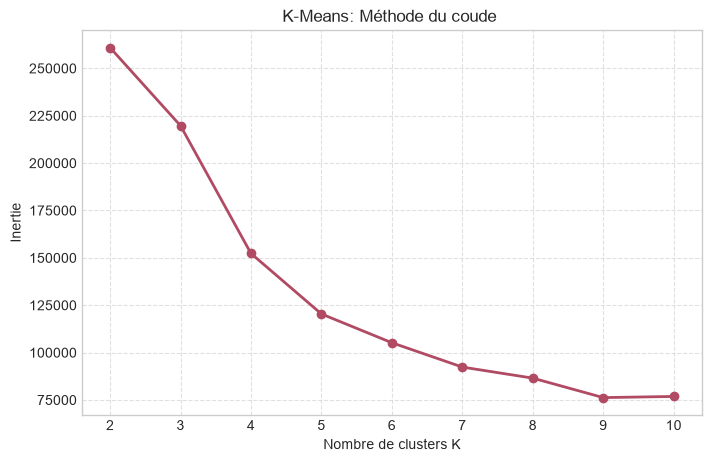

In [44]:
#methode du coude (elbow method)
inertias = []
k_values = range(2, 11)

for k in k_values:

    model = KMeans(
        n_clusters=k,
        init="random",
        n_init=10,
        random_state=42
    )

    model.fit(X)

    inertias.append(model.inertia_)

#traçage du graphique
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertias, marker="o", color="#b14a63", linewidth=2)

plt.xlabel("Nombre de clusters K")
plt.ylabel("Inertie")
plt.title("K-Means: Méthode du coude ")
plt.grid(True, linestyle="--", alpha=0.6)

plt.savefig("../clustering/graphiques/coude_kmeans.png", dpi=300, bbox_inches="tight")
plt.show()


### Coefficient de silhouette

Le coefficient de silhouette est calculé pour les mêmes valeurs de K. Son calcul exact étant quadratique, il est estimé sur un échantillon de 5000 observations avec une graine fixe, ce qui préserve la comparabilité entre les modèles pour un coût raisonnable. Une valeur proche de 1 indique des groupes compacts et bien séparés.

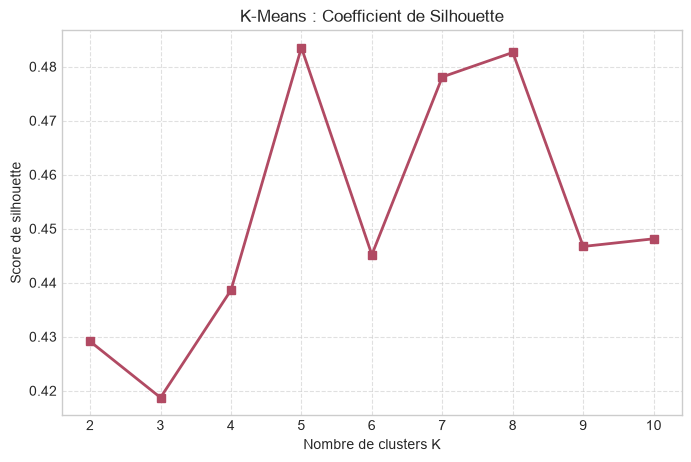

In [45]:
#Coefficient de silhouette
from sklearn.metrics import silhouette_score

silhouettes = []

for k in range(2, 11):

    model = KMeans(
        n_clusters=k,
        init="random",
        n_init=10,
        random_state=42
    )

    labels = model.fit_predict(X)

    score = silhouette_score(
        X,
        labels,
        sample_size=min(5000, len(X)),
        random_state=42
    )

    silhouettes.append(score)


# Visualisation propre
plt.figure(figsize=(8, 5))
plt.plot(list(range(2, 11)), silhouettes, marker="s", color="#b14a63", linewidth=2)

plt.xlabel("Nombre de clusters K")
plt.ylabel("Score de silhouette")
plt.title("K-Means : Coefficient de Silhouette")
plt.grid(True, linestyle="--", alpha=0.6)

plt.savefig("../clustering/graphiques/silhouette_kmeans.png", dpi=300, bbox_inches="tight")
plt.show()

### Synthèse des critères

Le tableau rassemble l'inertie, la silhouette et le temps pour chaque K avec l'initialisation KMeans++. La silhouette reste voisine de 0,43 pour K égal à 2, 3 et 4, puis progresse nettement jusqu'à 0,48 pour K égal à 5, alors que l'inertie continue de diminuer. Passé ce seuil, les scores fluctuent entre 0,47 et 0,51 avec un gain d'inertie de plus en plus faible par rapport à la complexité ajoutée, et les temps de calcul restent négligeables. Même si K égal à 10 obtient la silhouette la plus élevée, il produirait des groupes trop fins pour être interprétés. Nous retenons donc K égal à 5 comme compromis entre qualité de séparation et lisibilité métier.

In [46]:
#Détermination du meilleur K en combinant les deux méthodes
import pandas as pd
import time

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Valeurs de K à tester
k_values = range(2, 11)

results = []

for k in k_values:

    # Création du modèle K-Means
    model = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        random_state=42
    )

    # Mesurer le temps d'exécution
    start = time.time()

    # Entraîner le modèle
    labels = model.fit_predict(X)

    end = time.time()
    execution_time = end - start

    # Calculer la silhouette
    silhouette = silhouette_score(
        X,
        labels,
        sample_size=min(5000, len(X)),
        random_state=42
    )

    # Enregistrer les résultats
    results.append({
        "K": k,
        "Inertie": model.inertia_,
        "Silhouette": silhouette,
        "Temps (secondes)": execution_time
    })

# Afficher le tableau final
resultats_k = pd.DataFrame(results)

display(resultats_k.round(4))

,K,Inertie,Silhouette,Temps (secondes)
0,2,260945.3247,0.4291,0.1422
1,3,192972.0638,0.4339,0.3848
2,4,151758.0609,0.4327,0.1943
3,5,119654.2285,0.4773,0.2237
4,6,104630.4736,0.4952,0.2383
5,7,91649.3318,0.4711,0.3044
6,8,80729.4723,0.4728,0.3927
7,9,72523.1290,0.4921,0.4189
8,10,62018.6637,0.5117,0.4621


## KMeans++

Nous ajustons maintenant le modèle avec K égal à 5 et l'initialisation KMeans++, qui choisit des centres initiaux dispersés en favorisant les points éloignés des centres déjà sélectionnés. L'inertie obtenue, d'environ 119654, est cohérente avec celle du tableau de synthèse, et la convergence n'exige que 4 itérations. Le modèle de référence utilisant désormais le même nombre de clusters, son inertie et son nombre d'itérations sont directement comparables à ceux de KMeans++.

In [47]:
#Expérimenter K-Means++
kmeans_pp = KMeans(
    n_clusters=5,
    init="k-means++",
    n_init=10,
    max_iter=300,
    random_state=42
)

start = time.perf_counter()

labels_kmeanspp = kmeans_pp.fit_predict(X)

time_kmeanspp = time.perf_counter() - start

print("Inertie :", kmeans_pp.inertia_)
print("Itérations :", kmeans_pp.n_iter_)
print("Temps :", time_kmeanspp)

Inertie : 119654.22848780919
Itérations : 4
Temps : 0.28235080000013113


### Robustesse de l'initialisation

Pour comparer proprement les deux stratégies d'initialisation, nous fixons K à 5, désactivons les répétitions en posant n_init égal à 1 et faisons varier cinq graines aléatoires. Cette configuration expose directement la sensibilité de chaque méthode au hasard, ce que masquerait un n_init élevé. Pour chaque essai, nous enregistrons l'inertie, le nombre d'itérations et le temps d'exécution.

In [48]:
seeds = [10, 20, 30, 40, 50]

results = []

for seed in seeds:

    for initialization in ["random", "k-means++"]:

        model = KMeans(
            n_clusters=5,
            init=initialization,
            n_init=1,
            random_state=seed
        )

        start = time.perf_counter()

        model.fit(X)

        elapsed = time.perf_counter() - start

        results.append({
            "seed": seed,
            "initialization": initialization,
            "inertia": model.inertia_,
            "iterations": model.n_iter_,
            "time": elapsed
        })

comparison_init = pd.DataFrame(results)

### Lecture des résultats

Le résumé statistique montre que KMeans++ obtient une inertie moyenne d'environ 123516 avec un écart type de 5295, contre 156183 et 32586 pour l'initialisation aléatoire. Il converge aussi plus vite, avec environ 3 itérations en moyenne contre près de 12, alors que les temps de calcul restent comparables. KMeans++ est donc à la fois plus stable et plus efficace, ce qui justifie de le préférer.

In [49]:
print(
    comparison_init.groupby("initialization")[
        ["inertia", "iterations", "time"]
    ].agg(["mean", "std"])
)

                      inertia               iterations                time  \
                         mean           std       mean       std      mean   
initialization                                                               
k-means++       123516.383730   5294.739906        3.2  1.095445  0.048218   
random          156182.564821  32585.212342       11.8  7.596052  0.055261   

                          
                     std  
initialization            
k-means++       0.008758  
random          0.018418  


## Score d'anomalie fondé sur la distance au centroïde

Le partitionnement ne produit pas directement de détection, nous construisons donc un score d'anomalie. L'idée est qu'une journée normale se situe près du centre de son cluster, alors qu'une journée atypique en est éloignée. Pour chaque observation, nous retenons la distance euclidienne à son propre centroïde, obtenue grâce à la méthode transform des modèles, d'abord pour KMeans puis pour KMeans++.

In [50]:
#Premier score d'anomalie K-Means
#pour Kmeans:
from sklearn.metrics import pairwise_distances

distances = kmeans.transform(X)

labels = labels_kmeans

anomaly_score_kmeans = distances[
    np.arange(len(X)),
    labels
]

#pour kmeans++:
distances_pp = kmeans_pp.transform(X)

anomaly_score_kmeanspp = distances_pp[
    np.arange(len(X)),
    labels_kmeanspp
]

### Normalisation par percentile

La fonction suivante convertit les scores bruts en rangs percentiles compris entre 0 et 1. Cette normalisation rend comparables les scores issus d'algorithmes différents, dont les distances n'ont pas la même échelle, et facilite l'agrégation ultérieure.

In [51]:
def percentile_anomaly_score(scores):

    return (
        pd.Series(scores)
        .rank(pct=True)
        .to_numpy()
    )

### Seuil d'alerte

Une journée est signalée lorsque son score appartient aux 2 pour cent les plus élevés. Ce seuil, légèrement supérieur à la proportion réelle d'attaques de 1 pour cent, constitue un compromis entre la capacité à retrouver les attaques et un volume d'alertes raisonnable pour un analyste. Le même seuil est appliqué à tous les algorithmes afin de garantir une comparaison équitable.

In [52]:
threshold = 0.98

# Flag pour K-Means
flag_kmeans = (
    anomaly_score_kmeans >= np.quantile(anomaly_score_kmeans, threshold)
).astype(int)

# Flag pour K-Means++
flag_kmeanspp = (
    anomaly_score_kmeanspp >= np.quantile(anomaly_score_kmeanspp, threshold)
).astype(int)

# Classification ascendante hiérarchique

## Dendrogramme

La CAH agglomérative construit les groupes en fusionnant progressivement les observations les plus proches. Le critère de Ward est retenu car il minimise l'augmentation de la variance à l'intérieur des groupes, ce qui le rend cohérent avec l'objectif de KMeans. La matrice de liaison étant coûteuse en mémoire sur 30000 points, elle est calculée sur un échantillon aléatoire de 1000 observations, suffisant pour visualiser la structure. Le dendrogramme est tronqué à 30 groupes terminaux pour rester lisible, et la hauteur des fusions aide à estimer un nombre de clusters pertinent.

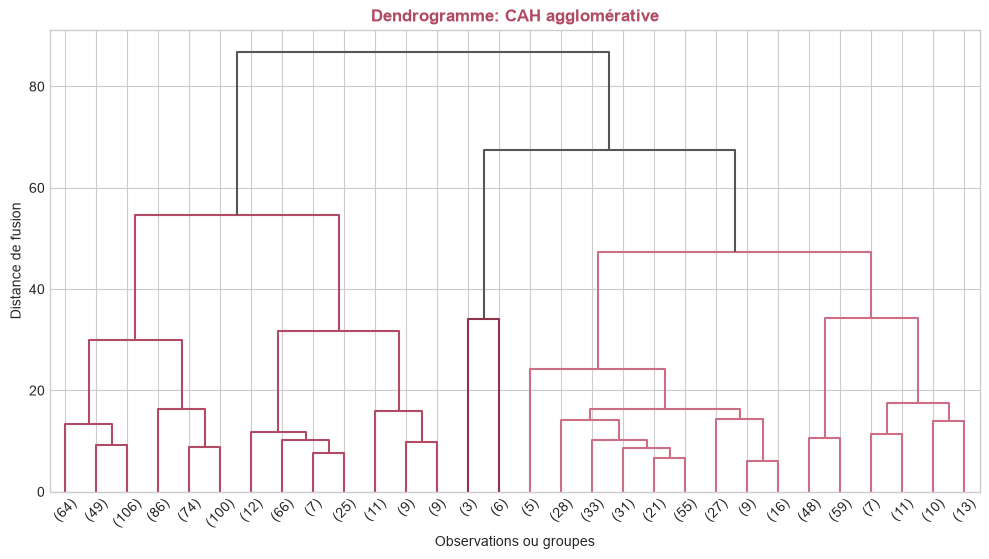

In [53]:
from scipy.cluster.hierarchy import (
    linkage,
    dendrogram,
    set_link_color_palette
)
import matplotlib.pyplot as plt

sample_size = min(1000, len(X))

X_sample = X.sample(
    n=sample_size,
    random_state=42
)

Z = linkage(
    X_sample,
    method="ward"
)

custom_palette = [
    "#b14a63",  
    "#8e344a",  
    "#cc6f85",  
    "#e298a8"   
]
set_link_color_palette(custom_palette)

plt.figure(figsize=(12, 6))

dendrogram(
    Z,
    truncate_mode="lastp",
    p=30,
    above_threshold_color="#555555",  
    color_threshold=None             
)

# Réinitialise la palette par défaut de SciPy pour les futurs tracés
set_link_color_palette(None)

plt.title("Dendrogramme: CAH agglomérative", color="#b14a63", fontweight="bold")
plt.xlabel("Observations ou groupes")
plt.ylabel("Distance de fusion")

plt.savefig(
    "../clustering/graphiques/dendrogramme_cah.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Graphe de connectivité

Pour appliquer la CAH à l'ensemble des observations, nous contraignons les fusions à l'aide d'un graphe des 15 plus proches voisins. Cette contrainte de connectivité réduit le coût de calcul et impose que seuls des points voisins puissent être regroupés, ce qui produit des clusters localement cohérents.

In [54]:
#Construire le graphe de voisinage
from sklearn.neighbors import kneighbors_graph

connectivity = kneighbors_graph(
    X,
    n_neighbors=15,
    include_self=False
)

## Exécution de la CAH agglomérative

Le modèle est lancé avec cinq clusters, le critère de Ward et la connectivité précédente. L'avertissement affiché indique que le graphe comporte 58 composantes connexes, que sklearn relie automatiquement afin de ne pas interrompre la construction de l'arbre, ce qui ne remet pas en cause le résultat. Le temps de calcul atteint environ 32 secondes, soit plus de cent fois celui de KMeans, ce qui illustre le coût élevé des méthodes hiérarchiques sur un jeu de cette taille.

In [55]:
#Exécuter la CAH sur toutes les observations
from sklearn.cluster import AgglomerativeClustering

cah_agglo = AgglomerativeClustering(
    n_clusters=5,
    linkage="ward",
    connectivity=connectivity
)

start = time.perf_counter()

labels_agglo = cah_agglo.fit_predict(X)

time_agglo = time.perf_counter() - start

print("Temps :", time_agglo)

print(
    "Clusters :",
    np.unique(labels_agglo)
)

c:\Users\ASMA\Documents\chronobank2\chronoBank\.venv\Lib\site-packages\sklearn\cluster\_agglomerative.py:322: UserWarning: the number of connected components of the connectivity matrix is 58 > 1. Completing it to avoid stopping the tree early.
  connectivity, n_connected_components = _fix_connectivity(


Temps : 31.776891899993643
Clusters : [0 1 2 3 4]


## Choix du nombre de clusters pour la CAH

Nous testons la CAH pour K de 2 à 8 et calculons à chaque fois la silhouette, l'indice de Davies Bouldin, pour lequel une valeur faible traduit des groupes mieux séparés, ainsi que le temps d'exécution. Les résultats sont conservés dans le tableau agglo_results, qui permet de vérifier que la valeur de cinq clusters, retenue pour rester cohérent avec KMeans++, convient également à cette méthode.

In [56]:
#Tester plusieurs valeurs de K
k_values = range(2, 9)

agglo_results = []

for k in k_values:

    model = AgglomerativeClustering(
        n_clusters=k,
        linkage="ward",
        connectivity=connectivity
    )

    start = time.perf_counter()

    labels = model.fit_predict(X)

    elapsed = time.perf_counter() - start

    score = silhouette_score(
        X,
        labels,
        sample_size=min(5000, len(X)),
        random_state=42
    )

    db_score = davies_bouldin_score(
        X,
        labels
    )

    agglo_results.append({
        "k": k,
        "silhouette": score,
        "davies_bouldin": db_score,
        "time": elapsed
    })

agglo_results = pd.DataFrame(agglo_results)

c:\Users\ASMA\Documents\chronobank2\chronoBank\.venv\Lib\site-packages\sklearn\cluster\_agglomerative.py:322: UserWarning: the number of connected components of the connectivity matrix is 58 > 1. Completing it to avoid stopping the tree early.
  connectivity, n_connected_components = _fix_connectivity(
c:\Users\ASMA\Documents\chronobank2\chronoBank\.venv\Lib\site-packages\sklearn\cluster\_agglomerative.py:322: UserWarning: the number of connected components of the connectivity matrix is 58 > 1. Completing it to avoid stopping the tree early.
  connectivity, n_connected_components = _fix_connectivity(
c:\Users\ASMA\Documents\chronobank2\chronoBank\.venv\Lib\site-packages\sklearn\cluster\_agglomerative.py:322: UserWarning: the number of connected components of the connectivity matrix is 58 > 1. Completing it to avoid stopping the tree early.
  connectivity, n_connected_components = _fix_connectivity(
c:\Users\ASMA\Documents\chronobank2\chronoBank\.venv\Lib\site-packages\sklearn\cluster\_

## Score d'anomalie de la CAH agglomérative

Contrairement à KMeans, la CAH ne fournit pas de centroïdes. Nous les calculons donc manuellement comme la moyenne des observations de chaque cluster, puis mesurons la distance euclidienne de chaque point au centre de son groupe. Le score est ensuite converti en percentile avec la fonction définie plus haut, et le même seuil de 98 pour cent produit les alertes.

In [57]:
#Calculer le score d'anomalie de la CAH agglomérative
#Calculer les centroïdes
centroids_agglo = {}

for cluster_id in np.unique(labels_agglo):

    cluster_points = X[
        labels_agglo == cluster_id
    ]

    centroids_agglo[cluster_id] = (
        cluster_points.mean(axis=0).values
    )

#Calculer les distances aux centroïdes
from scipy.spatial.distance import cdist

anomaly_score_agglo = np.zeros(len(X))

for cluster_id, centroid in centroids_agglo.items():

    indices = np.where(
        labels_agglo == cluster_id
    )[0]

    distances = cdist(
        X.iloc[indices],
        centroid.reshape(1, -1),
        metric="euclidean"
    ).ravel()

    anomaly_score_agglo[indices] = distances

#Normaliser
score_agglo = percentile_anomaly_score(
    anomaly_score_agglo
)
#determiner les flags
flag_agglo = (
    score_agglo >= 0.98
).astype(int)

# CAH divisive

## Bisecting KMeans

L'approche divisive procède à l'inverse de l'approche ascendante : on part d'un groupe unique que l'on scinde progressivement. Une CAH divisive exacte est inabordable en calcul sur 30000 points, nous utilisons donc BisectingKMeans de sklearn, qui divise à chaque étape le cluster d'inertie maximale en deux groupes grâce à KMeans. Avec quatre clusters, l'inertie finale d'environ 151759 est pratiquement identique à celle de KMeans++ pour K égal à 4 dans le tableau de synthèse, pour un temps de calcul de l'ordre d'un quart de seconde.

In [58]:
#Importer la classe BisectingKMeans
from sklearn.cluster import BisectingKMeans
#Créer le modèle
cah_divisive = BisectingKMeans(
    n_clusters=4,
    init="k-means++",
    n_init=10,
    random_state=42,
    bisecting_strategy="biggest_inertia"
)
#Entraîner le modèle
start = time.perf_counter()

labels_divisive = cah_divisive.fit_predict(X)

time_divisive = time.perf_counter() - start

print("Temps :", time_divisive)

print(
    "Inertie :",
    cah_divisive.inertia_
)


Temps : 0.24667410005349666
Inertie : 151758.87917232816


## Choix du nombre de clusters pour la CAH divisive

Comme pour la CAH agglomérative, K varie de 2 à 8 et nous enregistrons l'inertie, la silhouette, l'indice de Davies Bouldin et le temps. Ce tableau, stocké dans divisive_results, permet de comparer la méthode aux autres sur des critères communs.

In [59]:
# Tester plusieurs nombres de clusters
divisive_results = []

for k in range(2, 9):

    model = BisectingKMeans(
        n_clusters=k,
        n_init=10,
        random_state=42,
        bisecting_strategy="biggest_inertia"
    )

    start = time.perf_counter()

    labels = model.fit_predict(X)

    elapsed = time.perf_counter() - start

    silhouette = silhouette_score(
        X,
        labels,
        sample_size=min(5000, len(X)),
        random_state=42
    )

    db_score = davies_bouldin_score(
        X,
        labels
    )

    divisive_results.append({
        "k": k,
        "inertia": model.inertia_,
        "silhouette": silhouette,
        "davies_bouldin": db_score,
        "time": elapsed
    })

divisive_results = pd.DataFrame(
    divisive_results
)

## Score d'anomalie de la CAH divisive

Les centres du modèle sont disponibles dans l'attribut cluster_centers_. La distance de chaque observation à son centre est calculée, convertie en percentile, puis seuillée à 98 pour cent selon la même procédure que pour les autres algorithmes.

In [60]:
#Calculer les scores d'anomalie

distances_divisive = cdist(
    X,
    cah_divisive.cluster_centers_,
    metric="euclidean"
)

anomaly_score_divisive = distances_divisive[
    np.arange(len(X)),
    labels_divisive
]
score_divisive = percentile_anomaly_score(
    anomaly_score_divisive
)

flag_divisive = (
    score_divisive >= 0.98
).astype(int)

# Visualisation et interprétation des clusters

## Réduction de dimension par PCA

Pour représenter en deux dimensions des données comportant treize variables, nous projetons les observations sur les deux premières composantes principales. Elles expliquent respectivement 41 et 19 pour cent de la variance, soit 60 pour cent au total. La projection est donc informative mais partielle, et certains recouvrements visuels entre clusters peuvent n'être qu'un effet de la réduction de dimension.

In [61]:
#visualisation avec PCA
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X)

print(
    "Variance expliquée :",
    pca.explained_variance_ratio_
)

print(
    "Variance totale :",
    pca.explained_variance_ratio_.sum()
)

Variance expliquée : [0.41423434 0.19004888]
Variance totale : 0.6042832266269763


## Comparaison visuelle des quatre méthodes

Quatre nuages de points partagent la même projection, un par algorithme, avec une palette unique pour assurer la lisibilité. Cette représentation permet de comparer d'un coup d'oeil la manière dont chaque méthode découpe l'espace et de repérer les groupes isolés, qui correspondent aux comportements les plus atypiques. La figure est enregistrée en haute résolution pour le rapport.

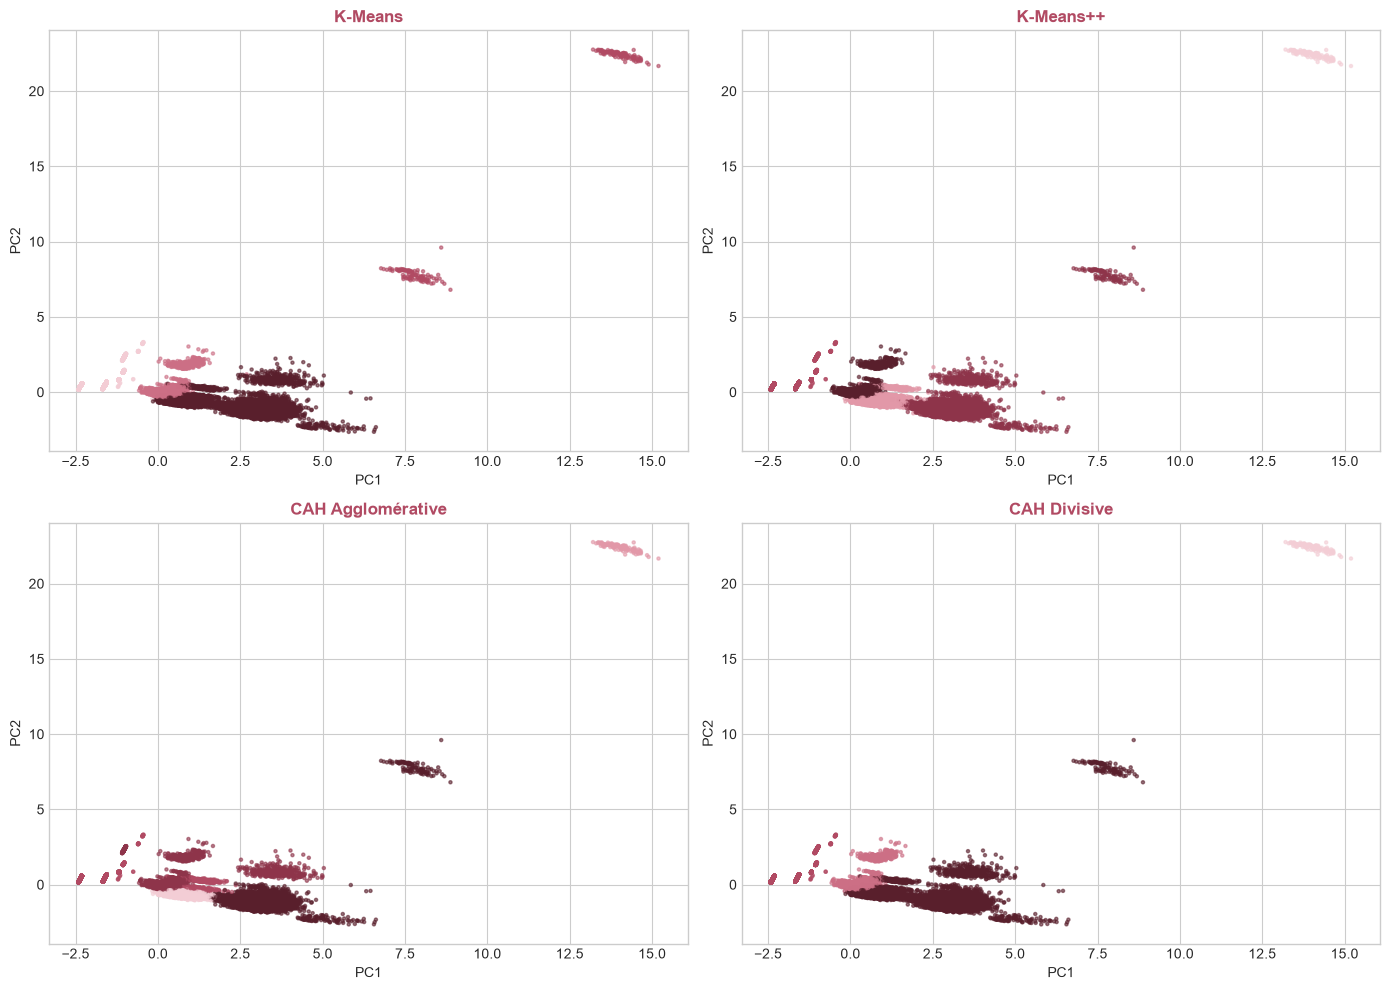

In [62]:

#Créer quatre graphiques
#Un graphique pour chaque méthode.
from matplotlib.colors import ListedColormap

# Palette personnalisée basée sur #b14a63 (identique à celle du dendrogramme)
custom_colors = [
    "#b14a63",  
    "#8e344a",  
    "#cc6f85",  
    "#e298a8",   
    "#591f2c",  # (au cas où k > 4)
    "#f3cdd5"   # (au cas où k > 5)
]
custom_cmap = ListedColormap(custom_colors)

# Créer 4 graphes pour visualiser les clusters
fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 10)
)

models_labels = [
    ("K-Means", labels_kmeans),
    ("K-Means++", labels_kmeanspp),
    ("CAH Agglomérative", labels_agglo),
    ("CAH Divisive", labels_divisive)
]

for ax, (name, labels) in zip(
    axes.flatten(),
    models_labels
):
    scatter = ax.scatter(
        X_pca[:, 0],
        X_pca[:, 1],
        c=labels,
        cmap=custom_cmap,
        s=5,
        alpha=0.6
    )

    ax.set_title(name, color="#b14a63", fontweight="bold")
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")

plt.tight_layout()

plt.savefig(
    "../clustering/graphiques/pca_clusters.png",
    dpi=300
)

plt.show()

## Profil moyen des clusters

Pour donner un sens métier aux groupes, nous calculons la moyenne de chaque indicateur par cluster. Les variables étant centrées et réduites, une valeur positive signifie un niveau supérieur à la moyenne générale et une valeur négative un niveau inférieur.

### KMeans

Avec cinq clusters, la lecture des moyennes consiste à repérer d'abord le groupe aux valeurs extrêmes sur les échecs de connexion, les appareils nouveaux, les opérations à l'étranger, l'activité nocturne et le rapport de montant, profil compatible avec un comportement frauduleux. Les autres groupes sont ensuite caractérisés par leur niveau d'activité, leur part de connexions sans transaction et leurs montants, ce qui permet de distinguer des usages ordinaires.

In [ ]:
#Créer une table associant les labels de clustering aux variables originales
#pour kmeans
result_interpretation = df[feature_columns].copy()

result_interpretation["cluster_kmeans"] = kmeans.labels_

interpretation_kmeans = result_interpretation.groupby(
    "cluster_kmeans"
).mean()

print("Interprétation K-Means :")
display(interpretation_kmeans)

### KMeans++

Avec cinq clusters, le profil atypique est isolé de façon plus nette : le cluster 4 présente des valeurs supérieures de plus de quinze écarts types à la moyenne pour les appareils nouveaux et les opérations à l'étranger, ainsi qu'un nombre d'échecs de connexion proche de douze écarts types au dessus de la moyenne générale. Les quatre autres clusters décrivent des usages légitimes : faible activité, connexions sans transaction, et deux groupes à fortes transactions et montants élevés qui se distinguent par l'espacement des opérations, large pour l'un et très resserré pour l'autre.

In [64]:
#pour kmeans++:
result_interpretation = df[feature_columns].copy()

result_interpretation["cluster_kmeans++"] = kmeans_pp.labels_

interpretation_kmeans = result_interpretation.groupby(
    "cluster_kmeans++"
).mean()

print("Interprétation K-Means++ :")
display(interpretation_kmeans)

Interprétation K-Means++ :


,n_events,n_tx,n_login,n_failed,n_new_device,n_foreign,pct_night,hour_mean,amount_mean,amount_max,amount_ratio,min_gap,mean_gap
cluster_kmeans++,,,,,,,,,,,,,
0,-0.762409,-0.720488,-0.358629,-0.099651,-0.077199,-0.077199,-0.163580,0.018673,-0.792807,-0.792947,-0.718440,-0.754072,-0.763833
1,1.067335,1.258687,0.516431,0.026299,0.021310,0.021310,0.158913,-0.013545,1.218462,1.228087,1.111908,1.252782,1.287658
2,-0.048556,0.835105,-1.007450,-0.169159,-0.077199,-0.077199,0.175074,0.015171,1.208148,1.189320,0.982381,-0.752172,-0.762011
3,0.855014,-0.720488,1.469008,0.225326,-0.077199,-0.077199,0.040692,-0.004324,-0.792807,-0.792947,-0.718440,1.318757,1.282512
4,3.130253,1.239130,3.512542,11.721186,15.601664,15.601664,3.368421,-2.188581,2.134230,2.202081,5.964211,0.502168,0.960315


### CAH agglomérative

Les profils sont très proches de ceux de KMeans++ : le cluster 2 reproduit exactement les moyennes extrêmes du groupe atypique, ce qui indique que ces journées forment une structure robuste, indépendante de l'algorithme choisi. Les autres clusters se répartissent entre faible activité, connexions sans transaction et transactions à montants élevés, avec ou sans resserrement des intervalles entre opérations.

In [66]:
# pour CAH Agglomérative :
result_interpretation = df[feature_columns].copy()
result_interpretation["cluster_agglo"] = labels_agglo

interpretation_agglo = result_interpretation.groupby(
    "cluster_agglo"
).mean()

print("Interprétation CAH Agglomérative :")
display(interpretation_agglo)

Interprétation CAH Agglomérative :


,n_events,n_tx,n_login,n_failed,n_new_device,n_foreign,pct_night,hour_mean,amount_mean,amount_max,amount_ratio,min_gap,mean_gap
cluster_agglo,,,,,,,,,,,,,
0,-0.747617,-0.665573,-0.393314,-0.162859,-0.077199,-0.077199,-0.023924,0.018991,-0.721936,-0.722739,-0.657161,-0.754072,-0.763833
1,0.838508,-0.570066,1.382937,0.762739,-0.077199,-0.077199,0.022941,0.001721,-0.621963,-0.622480,-0.568468,1.192460,1.170253
2,3.130253,1.239130,3.512542,11.721186,15.601664,15.601664,3.368421,-2.188581,2.134230,2.202081,5.964211,0.502168,0.960315
3,1.058960,1.269263,0.486820,-0.167856,0.025898,0.025898,0.163204,-0.014677,1.218681,1.229019,1.115357,1.256639,1.287755
4,-0.050123,0.833335,-1.007644,-0.170189,-0.077199,-0.077199,-0.351656,0.009317,1.207247,1.188292,0.976639,-0.754072,-0.763833


### CAH divisive

Avec quatre clusters, la méthode retrouve elle aussi le groupe atypique, aux moyennes identiques à celles des deux modèles précédents, et l'isole dans un cluster à part. Les trois autres groupes rassemblent les usages légitimes : faible activité, connexions sans transaction et transactions à montants élevés regroupées en un seul cluster, sans distinction du rythme des opérations.

In [67]:
# pour CAH Divisive :
result_interpretation = df[feature_columns].copy()
result_interpretation["cluster_divisive"] = labels_divisive

interpretation_divisive = result_interpretation.groupby(
    "cluster_divisive"
).mean()

print("Interprétation CAH Divisive :")
display(interpretation_divisive)

Interprétation CAH Divisive :


,n_events,n_tx,n_login,n_failed,n_new_device,n_foreign,pct_night,hour_mean,amount_mean,amount_max,amount_ratio,min_gap,mean_gap
cluster_divisive,,,,,,,,,,,,,
0,-0.762361,-0.720382,-0.358673,-0.099656,-0.077199,-0.077199,-0.163593,0.018689,-0.792723,-0.792864,-0.718387,-0.754072,-0.763833
1,0.855014,-0.720488,1.469008,0.225326,-0.077199,-0.077199,0.040692,-0.004324,-0.792807,-0.792947,-0.718440,1.318757,1.282512
2,0.675725,1.110035,-0.018360,-0.042295,-0.013261,-0.013261,0.164630,-0.003487,1.214909,1.214548,1.066530,0.549163,0.568347
3,3.130253,1.239130,3.512542,11.721186,15.601664,15.601664,3.368421,-2.188581,2.134230,2.202081,5.964211,0.502168,0.960315


# Évaluation comparative des algorithmes

## Tableau de synthèse

Nous réunissons dans un même tableau les indicateurs internes, à savoir l'inertie, le nombre d'itérations, le temps et la silhouette, ainsi que les indicateurs externes calculés avec les étiquettes simulées : score F1, nombre de faux positifs et taux de faux positifs. Les valeurs indisponibles, comme l'inertie de la CAH agglomérative, restent vides car l'algorithme n'expose pas cet attribut. Le tableau est exporté au format CSV pour être conservé avec les autres livrables.

In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import silhouette_score, f1_score, confusion_matrix


# RÉCUPÉRATION ET CALCUL DES MÉTRIQUES

sample_size_eval = min(5000, len(X))

#  Itérations
iter_km = getattr(kmeans, 'n_iter_', np.nan)
iter_kmpp = getattr(kmeans_pp, 'n_iter_', np.nan)
iter_div = getattr(cah_divisive, 'n_iter_', np.nan)
iter_agglo = np.nan

# Inerties 
inertia_km = getattr(kmeans, 'inertia_', np.nan)
inertia_kmpp = getattr(kmeans_pp, 'inertia_', np.nan)
inertia_div = getattr(cah_divisive, 'inertia_', np.nan)
inertia_agglo = np.nan

# Silhouettes 
sil_km = silhouette_score(X, labels_kmeans, sample_size=sample_size_eval, random_state=42)
sil_kmpp = silhouette_score(X, labels_kmeanspp, sample_size=sample_size_eval, random_state=42)
sil_agglo = silhouette_score(X, labels_agglo, sample_size=sample_size_eval, random_state=42)
sil_div = silhouette_score(X, labels_divisive, sample_size=sample_size_eval, random_state=42)

# F1-scores vis-à-vis des attaques simulées 
f1_km = f1_score(y_true, flag_kmeans)
f1_kmpp = f1_score(y_true, flag_kmeanspp)
f1_agg = f1_score(y_true, flag_agglo)
f1_div = f1_score(y_true, flag_divisive)

# Faux Positifs (FP) et Taux de Faux Positifs (FPR) 
def get_fp_stats(flags):
    tn, fp, fn, tp = confusion_matrix(y_true, flags).ravel()
    fpr = (fp / (fp + tn) * 100) if (fp + tn) > 0 else 0.0
    return int(fp), round(fpr, 2)

fp_km, fpr_km = get_fp_stats(flag_kmeans)
fp_kmpp, fpr_kmpp = get_fp_stats(flag_kmeanspp)
fp_agg, fpr_agg = get_fp_stats(flag_agglo)
fp_div, fpr_div = get_fp_stats(flag_divisive)

# TABLEAU COMPARATIF COMPLET
comparison_complete = pd.DataFrame({
    "Algorithm": ["K-Means", "K-Means++", "CAH Agglomerative", "CAH Divisive"],
    "Inertie": [inertia_km, inertia_kmpp, inertia_agglo, inertia_div],
    "Iterations": [iter_km, iter_kmpp, iter_agglo, iter_div],
    "Temps (s)": [time_kmeans, time_kmeanspp, time_agglo, time_divisive],
    "Silhouette": [sil_km, sil_kmpp, sil_agglo, sil_div],
    "F1-Score": [f1_km, f1_kmpp, f1_agg, f1_div],
    "Faux Positifs (FP)": [fp_km, fp_kmpp, fp_agg, fp_div],
    "Taux FP (%)": [fpr_km, fpr_kmpp, fpr_agg, fpr_div]
})

# EXPORT CSV ET AFFICHAGE
comparison_complete.to_csv("../clustering/comparaiso_algorithmes.csv", index=False)
print("Fichier 'comparaiso_algorithmes.csv' sauvegardé avec succès dans clustering")

display(comparison_complete.round(4))

## Lecture des résultats

Sur le plan de la géométrie des clusters, KMeans++ obtient une silhouette de 0,477, la CAH agglomérative 0,453 et la CAH divisive 0,433, cette dernière utilisant quatre clusters. La CAH agglomérative est de loin la plus coûteuse, avec environ 32 secondes, contre une fraction de seconde pour les autres méthodes. Sur le plan de la détection, KMeans++, la CAH agglomérative et la CAH divisive plafonnent autour d'un score F1 de 0,44, avec environ 400 faux positifs, soit un taux proche de 1,35 pour cent, et retrouvent environ 199 attaques sur 300. Cet écart avec un rappel complet s'explique vraisemblablement par le fait que, lorsque le comportement frauduleux forme un cluster dense et isolé, ses membres se trouvent proches de leur propre centroïde et obtiennent un score de distance faible, donc échappent au seuil. Le KMeans de référence, ajusté avec le même nombre de clusters que KMeans++, permet de lire dans le tableau si l'initialisation aléatoire modifie cette capacité de détection. Il faut enfin rappeler qu'une bonne silhouette n'implique pas une meilleure détection.

# Export des résultats

## Table consolidée

Les scores percentiles et les alertes de chaque algorithme sont réunis dans une table unique, res_clustering, identifiée par utilisateur et par jour, avec la vérité terrain pour la validation. Une colonne flags additionne les alertes des quatre méthodes et fournit un indicateur de consensus de 0 à 4 : plus il est élevé, plus la journée est jugée suspecte par plusieurs approches à la fois. La table est exportée au format CSV pour être exploitée par les étapes suivantes du projet, et la cellule recalcule les scores manquants afin de rester exécutable isolément.

In [ ]:

# CONSTRUIRE LE FICHIER res_clustering.csv


# Sécurité : calcul/normalisation des scores percentiles s'ils ne sont pas déjà créés
if "score_kmeans" not in locals():
    score_kmeans = percentile_anomaly_score(anomaly_score_kmeans)

if "score_kmeanspp" not in locals():
    score_kmeanspp = percentile_anomaly_score(anomaly_score_kmeanspp)

# Création de la table de résultats à partir des métadonnées (user_id, day)
res_clustering = metadata.copy()

# Ajout optionnel mais recommandé de la vérité terrain pour validation
if "y_true" in locals():
    res_clustering["is_attack"] = y_true.values

# Ajout des scores d'anomalie normalisés (entre 0 et 1)
res_clustering["score_kmeans"] = score_kmeans
res_clustering["score_kmeanspp"] = score_kmeanspp
res_clustering["score_cah_agglo"] = score_agglo
res_clustering["score_cah_divisive"] = score_divisive

# Ajout des flags binaires (0 ou 1)
res_clustering["flag_kmeans"] = flag_kmeans
res_clustering["flag_kmeanspp"] = flag_kmeanspp
res_clustering["flag_cah_agglo"] = flag_agglo
res_clustering["flag_cah_divisive"] = flag_divisive

# Calcul de la colonne de consensus 'flags' (nombre d'algorithmes ayant alerté : 0 à 4)
flag_columns = [
    "flag_kmeans",
    "flag_kmeanspp",
    "flag_cah_agglo",
    "flag_cah_divisive"
]

res_clustering["flags"] = res_clustering[flag_columns].sum(axis=1)

# Export du fichier CSV
output_path = "../clustering/res_clustering.csv"
res_clustering.to_csv(output_path, index=False)

print(f"Fichier '{output_path.split('/')[-1]}' sauvegardé avec succès dans {output_path.rsplit('/', 1)[0]} !")
print(f"Dimensions du fichier généré : {res_clustering.shape}")

# 7. Affichage d'un aperçu
display(res_clustering.head())

## Aperçu des journées signalées

Un extrait des journées signalées par au moins un algorithme permet un contrôle visuel. Il confronte, pour chaque journée, les scores des algorithmes à l'étiquette réelle : les journées normales signalées correspondent aux faux positifs, inhérents à un seuil fixé sur un pourcentage de la population, ce qui motive l'usage du consensus pour hiérarchiser les alertes.

In [ ]:
# Afficher les journées signalées par au moins un modèle
display(res_clustering[res_clustering["flags"] > 0].head(10))

# Conclusion

Ce travail a permis de construire et de comparer quatre approches de partitionnement pour la détection de journées bancaires atypiques. Le choix de cinq clusters, appuyé par la silhouette et l'inertie, et l'initialisation KMeans++ se sont montrés plus stables et plus rapides que l'initialisation aléatoire. Les profils moyens révèlent de façon cohérente un groupe aux caractéristiques extrêmes, retrouvé par tous les algorithmes, qui correspond aux attaques simulées. La CAH agglomérative n'apporte pas d'avantage décisif au regard de son coût de calcul, et la CAH divisive reste proche de KMeans++ à quatre clusters. Le score de distance au centroïde présente néanmoins une limite : un cluster d'attaques dense échappe en partie au seuil, ce qui suggère de le compléter, en perspective, par la taille ou la rareté du cluster d'appartenance. Ces conclusions reposent sur des données simulées et devront être confirmées sur des données réelles. Les résultats consolidés sont exportés pour les étapes suivantes du projet.